# การจำแนกระดับความสุกของทุเรียนเพื่อการส่งออก (Durian Ripeness Classification)

### ที่มาและแนวคิด
ในโจทย์นี้ เราต้องการทำนายระดับความสุกของทุเรียนแต่ละผลใน `test.csv` ออกเป็น 4 ระดับตามลำดับความสุก: **`unripe` (อ่อน)**, **`ready` (แก่พร้อมตัด)**, **`ripe` (สุกพอดี)** และ **`overripe` (สุกเกิน)** โดยเรียนรู้จากข้อมูลการวัดด้วยชุดเครื่องวัดพกพาหลายเครื่องจากหลายสวนใน `train.csv` (~8,000 ผล)

จุดสำคัญที่ค้นพบและใช้แก้ปัญหาในเวอร์ชันปรับปรุง (v2):
* **Device Calibration & Domain Shift:** ข้อมูลชุด Train ใช้เครื่อง `D1`–`D4` ส่วน Test มีเครื่องใหม่ `D5` (35% ของ Test) และสวนใหม่ `F04` โดยแต่ละเครื่องมีสเกลต่างกันแบบเชิงเส้น $x_{\text{raw}} = a_{s,d} x_{\text{true}} + b_{s,d}$ รวมถึง `D3` บันทึกอุณหภูมิเป็น °F และ `weight_kg` มี 27 แถวที่จุดทศนิยมเลื่อน 1 ตำแหน่ง
* **Two-Stage EM Device Calibration:** สำหรับเครื่องที่เคยเห็น (`D1`–`D4`) ประมาณค่า $(a_{s,d}, b_{s,d})$ จาก 16 กลุ่ม `(variety, ripeness)` ภายใน Training Fold (ลด error จาก ~6 Hz เหลือ ~1.5 Hz) ส่วนเครื่องใหม่ (`D5`) ใช้ Balanced ALS + **EM Refinement** ด้วยความน่าจะเป็นทำนายรอบแรกเพื่อแก้ความเบี่ยงเบนของสัดส่วนสายพันธุ์บน `D5` (86% เป็นชะนีและพวงมณี)
* **MNAR Censoring & Bayesian Marginalization (บทที่ 8):** `shell_hardness` มีค่าว่าง 87.2% ในกลุ่ม `overripe` เพราะเซ็นเซอร์มีขีดจำกัดล่าง เราจึงสร้างฟีเจอร์ **Observed-Only Gaussian Bayes Posterior** ที่คำนวณ Likelihood เฉพาะเซ็นเซอร์ที่อ่านค่าได้จริงร่วมกับความน่าจะเป็นของค่าว่าง (ไม่เกิด Imputation Bias)
* **Physics & SNR Features:** ปรับลดอิทธิพลอุณหภูมิต่อกลิ่น (`aroma_index` สัมพันธ์กับ `ambient_temp` +0.183 ภายในคลาสเดียวกัน) และสร้างดัชนีความสุกรวมแบบถ่วงน้ำหนักตาม Fisher SNR รายสายพันธุ์
* **ตัวชี้วัด (Evaluation Metric):** **Macro-averaged F1** วัดผลควบคู่ทั้ง **Stratified 10-Fold CV**, **Leave-One-Device-Out (LODO) CV**, และ **Test-Variety-Weighted LODO CV** เพื่อให้สอดคล้องกับสัดส่วนสายพันธุ์ใน Test (`chanee` 32.3%, `puangmanee` 23.6%)

$$F_1^{(c)} = \frac{2 \cdot P_c \cdot R_c}{P_c + R_c}, \qquad \text{Macro-}F_1 = \frac{1}{4} \sum_{c \in \{\text{unripe, ready, ripe, overripe}\}} F_1^{(c)}$$

### 1. นำเข้าไลบรารีที่จำเป็น (Import Libraries)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize
from scipy.special import logsumexp

from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut
from sklearn.metrics import f1_score, log_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

# ตั้งค่าฟอนต์สำหรับกราฟให้แสดงภาษาไทยได้
plt.rcParams['font.family'] = ['Leelawadee UI', 'Tahoma', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
np.random.seed(SEED)
print("นำเข้าไลบรารีเรียบร้อยแล้ว")

นำเข้าไลบรารีเรียบร้อยแล้ว


### 2. โหลดและสำรวจข้อมูล (Load & Inspect Data)

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
sub_df = pd.read_csv('sample_submission.csv')

CLASSES = ['unripe', 'ready', 'ripe', 'overripe']
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
INV_LABEL_MAP = {i: c for i, c in enumerate(CLASSES)}
SENSORS = ['knock_freq_hz', 'stem_moisture_pct', 'shell_hardness', 'aroma_index', 'color_hue']
INVARIANT_NUMS = ['days_since_flowering', 'weight_kg', 'spine_spacing_mm', 'ambient_temp']

y_train = train_df['ripeness'].map(LABEL_MAP).values
devices_train = train_df['device_id'].values

print(f"จำนวนข้อมูล Train: {train_df.shape[0]} แถว | Test: {test_df.shape[0]} แถว")
print("\nสัดส่วนสายพันธุ์ใน Train vs Test (%):")
var_comp = pd.DataFrame({
    'Train (%)': train_df['variety'].value_counts(normalize=True) * 100,
    'Test (%)': test_df['variety'].value_counts(normalize=True) * 100,
    'Test D5 (%)': test_df[test_df['device_id'] == 'D5']['variety'].value_counts(normalize=True) * 100
}).round(2)
display(var_comp)

# คำนวณน้ำหนักสายพันธุ์เพื่อจำลองการประเมินผลให้ตรงกับสัดส่วนในชุด Test
test_var_share = test_df['variety'].value_counts(normalize=True)
train_var_share = train_df['variety'].value_counts(normalize=True)
variety_sample_weights = (train_df['variety'].map(test_var_share) / train_df['variety'].map(train_var_share)).values

จำนวนข้อมูล Train: 8000 แถว | Test: 3000 แถว

สัดส่วนสายพันธุ์ใน Train vs Test (%):


,Train (%),Test (%),Test D5 (%)
variety,,,
chanee,26.22,32.33,46.67
kanyao,19.89,14.07,4.10
monthong,39.57,30.00,10.00
puangmanee,14.31,23.60,39.24


### 3. การทำความสะอาดข้อมูลและระบบ Calibration เครื่องวัด (Data Cleaning & Two-Stage Device Calibration)
ฟังก์ชันด้านล่างจัดการความผิดปกติทั้งหมดแบบปลอด Data Leakage:
1. **ทำความสะอาดหน่วยวัด:** แก้ `weight_kg > 10` โดยหาร 10 และแปลง `ambient_temp > 50` (เครื่อง `D3`) จาก °F เป็น °C
2. **Balanced Unsupervised Affine Calibration (Stage 1):** ถ่วงน้ำหนักแต่ละคู่ `(device_id, variety)` ด้วย $\sqrt{n_{d,v}}$ และให้น้ำหนักสัดส่วนส่วนเบี่ยงเบนมาตรฐาน 2 เท่า เพื่อป้องกันสัดส่วนสายพันธุ์ที่ไม่สมดุลบนเครื่องใหม่ (`D5`) ทำให้ความชัน $a_d$ เอียง
3. **Supervised 16-Cell Calibration สำหรับเครื่องที่อยู่ใน Training Fold:** ใช้ค่าเฉลี่ยทั้ง 16 กลุ่ม `(variety, ripeness)` ของ `train_fold` เทียบกับเครื่องฐาน `D1` (หรือเครื่องแรกใน Fold) ทำให้เครื่องเดิม (`D1`–`D4` ซึ่งเป็น 65% ของ Test) ได้พารามิเตอร์ $(a_d, b_d)$ แม่นยำสูงสุด
4. **EM Calibration Refinement (Stage 2) สำหรับเครื่องใหม่:** นำความน่าจะเป็นทำนายรอบแรก $P^{(1)}(y_i=c|x_i)$ ของเครื่องใหม่มาคำนวณค่าคาดหวังบนสเกลมาตรฐานกลาง $\hat{\mu}_{s,i} = \sum_c P^{(1)}(y_i=c)\mu_{s,\text{ref}}(v_i, c)$ แล้วทำ Weighted Regression ปรับ $(a_d, b_d)$ ให้ตรงกับข้อมูลทั้ง 1,050 ผล

In [3]:
def clean_raw_df(df_in):
    df = df_in.copy()
    df['weight_outlier_flag'] = (df['weight_kg'] > 10).astype(float)
    df.loc[df['weight_kg'] > 10, 'weight_kg'] = df.loc[df['weight_kg'] > 10, 'weight_kg'] / 10.0
    mask_f = df['ambient_temp'] > 50
    df.loc[mask_f, 'ambient_temp'] = (df.loc[mask_f, 'ambient_temp'] - 32.0) * 5.0 / 9.0
    return df


def fit_balanced_unsupervised_cal(df_all, ref_device='D1'):
    """Stage 1: ประมาณค่า (a_d, b_d) แบบ Unsupervised ด้วยน้ำหนัก sqrt(count) เพื่อลดความเอนเอียงจากสัดส่วนสายพันธุ์"""
    params = {}
    varieties = sorted(df_all['variety'].unique())
    devices = sorted(df_all['device_id'].unique())
    if ref_device not in devices:
        ref_device = devices[0]

    for s in SENSORS:
        stats = df_all.groupby(['device_id', 'variety'])[s].agg(['count', 'mean', 'std']).reset_index()
        ref_stats = stats[stats['device_id'] == ref_device].set_index('variety')
        mu_v = ref_stats['mean'].to_dict()
        sig_v = ref_stats['std'].to_dict()
        a_d = {d: 1.0 for d in devices}
        b_d = {d: 0.0 for d in devices}

        for _ in range(30):
            for d in devices:
                if d == ref_device:
                    a_d[d], b_d[d] = 1.0, 0.0
                    continue
                sub = stats[stats['device_id'] == d]
                w = np.sqrt(sub['count'].values.astype(float))
                m_obs, s_obs = sub['mean'].values, sub['std'].values
                m_ref = np.array([mu_v[v] for v in sub['variety']])
                s_ref = np.array([sig_v[v] for v in sub['variety']])
                W = w.sum()
                m_ref_bar = np.sum(w * m_ref) / W
                m_obs_bar = np.sum(w * m_obs) / W
                num = np.sum(w * (m_ref - m_ref_bar) * (m_obs - m_obs_bar)) + 2.0 * np.sum(w * s_ref * s_obs)
                den = np.sum(w * (m_ref - m_ref_bar) ** 2) + 2.0 * np.sum(w * s_ref ** 2)
                a = num / den
                b = m_obs_bar - a * m_ref_bar
                a_d[d], b_d[d] = float(a), float(b)

            for v in varieties:
                sub = stats[stats['variety'] == v]
                w = sub['count'].values.astype(float)
                a_arr = np.array([a_d[d] for d in sub['device_id']])
                b_arr = np.array([b_d[d] for d in sub['device_id']])
                mu_v[v] = float(np.sum(w * a_arr * (sub['mean'].values - b_arr)) / np.sum(w * a_arr ** 2))
                sig_v[v] = float(np.sum(w * a_arr * sub['std'].values) / np.sum(w * a_arr ** 2))

        params[s] = {'a': a_d, 'b': b_d}
    return params


def fit_supervised_cal_for_seen_devices(tr_clean, y_tr, base_params, ref_device='D1'):
    """ปรับค่า (a_d, b_d) ให้แม่นยำขึ้นด้วย 16 กลุ่ม (variety, ripeness) เฉพาะเครื่องที่มีป้ายกำกับใน Training Fold"""
    params = {s: {'a': dict(base_params[s]['a']), 'b': dict(base_params[s]['b'])} for s in SENSORS}
    tmp = tr_clean.copy()
    tmp['_y'] = y_tr
    seen_devs = sorted(tmp['device_id'].unique())
    if ref_device not in seen_devs:
        ref_device = seen_devs[0]

    for s in SENSORS:
        piv_m = tmp.pivot_table(index=['variety', '_y'], columns='device_id', values=s, aggfunc='mean')
        piv_c = tmp.pivot_table(index=['variety', '_y'], columns='device_id', values=s, aggfunc='count')
        params[s]['a'][ref_device] = 1.0
        params[s]['b'][ref_device] = 0.0
        for d in seen_devs:
            if d == ref_device:
                continue
            valid = piv_m[[ref_device, d]].dropna()
            w = np.sqrt(piv_c.loc[valid.index, ref_device] * piv_c.loc[valid.index, d]).values
            a_sup, b_sup = np.polyfit(valid[ref_device].values, valid[d].values, 1, w=w)
            params[s]['a'][d] = float(a_sup)
            params[s]['b'][d] = float(b_sup)
    return params


def refine_unseen_device_em(tr_clean, y_tr, target_clean, target_probs, params, unseen_devices):
    """Stage 2 (EM Refinement): ปรับ (a_d, b_d) ของเครื่องใหม่โดยเทียบกับค่าคาดหวังบนสเกลมาตรฐานกลางจาก Soft Labels"""
    new_params = {s: {'a': dict(params[s]['a']), 'b': dict(params[s]['b'])} for s in SENSORS}
    tr_cal = tr_clean.copy()
    tr_cal['_y'] = y_tr
    for s in SENSORS:
        a_vec = tr_cal['device_id'].map(params[s]['a'])
        b_vec = tr_cal['device_id'].map(params[s]['b'])
        tr_cal[s + '_cal'] = (tr_cal[s] - b_vec) / a_vec

        # ตารางค่าเฉลี่ยมาตรฐานกลาง mu_ref[variety, class]
        cell_mean = tr_cal.pivot_table(index='variety', columns='_y', values=s + '_cal', aggfunc='mean')
        cell_std = tr_cal.pivot_table(index='variety', columns='_y', values=s + '_cal', aggfunc='std')

        for d in unseen_devices:
            mask = (target_clean['device_id'].values == d) & target_clean[s].notna().values
            if mask.sum() < 50:
                continue
            sub_v = target_clean.loc[mask, 'variety'].values
            sub_x = target_clean.loc[mask, s].values
            sub_p = target_probs[mask]

            # ค่าคาดหวังบนสเกลมาตรฐานกลางของทุเรียนแต่ละผล: E[x_cal | v, p]
            mu_mat = cell_mean.loc[sub_v].values
            x_exp = np.sum(sub_p * mu_mat, axis=1)
            # ความมั่นใจของคำทำนาย (ให้น้ำหนักมากกับผลที่มั่นใจสูง)
            conf = np.max(sub_p, axis=1) ** 2

            # ปรับแก้การหดตัวของความชันจากความแปรปรวนของตัวทำนาย (Errors-in-variables / Deming-style via variance matching)
            a_em, b_em = np.polyfit(x_exp, sub_x, 1, w=conf)
            # ผสมอย่างนุ่มนวลกับค่า Stage 1 เพื่อความเสถียร (70% EM + 30% Stage 1)
            a_old, b_old = params[s]['a'][d], params[s]['b'][d]
            a_blend = 0.70 * float(a_em) + 0.30 * a_old
            b_blend = float(np.average(sub_x - a_blend * x_exp, weights=conf))
            new_params[s]['a'][d] = a_blend
            new_params[s]['b'][d] = b_blend
    return new_params

train_clean = clean_raw_df(train_df)
test_clean = clean_raw_df(test_df)
print("เตรียมฟังก์ชันทำความสะอาดข้อมูลและ Two-Stage EM Calibration เรียบร้อยแล้ว")

เตรียมฟังก์ชันทำความสะอาดข้อมูลและ Two-Stage EM Calibration เรียบร้อยแล้ว


### 4. การสร้างฟีเจอร์เชิงฟิสิกส์และ Bayesian Observed-Only Likelihood (Feature Engineering)
จุดเด่นของการสร้างฟีเจอร์ในเวอร์ชันนี้คือ:
1. **Observed-Only Gaussian Bayes Posterior (บทที่ 8: Bayesian Learning):** คำนวณความน่าจะเป็นแบบเบย์ $P(y=c \mid x_{\text{obs}}, v)$ โดยคิด Likelihood **เฉพาะเซ็นเซอร์ที่ไม่มีค่าว่าง** ของผลทุเรียนนั้นๆ ร่วมกับ Bernoulli Likelihood ของ `shell_hardness_isna` (คำนวณแบบ Out-of-Fold ภายใน Training Fold เท่านั้น ป้องกัน Data Leakage 100%)
2. **Temperature-Adjusted Aroma:** หักล้างผลกระทบของอุณหภูมิแวดล้อมต่อค่ากลิ่น (`aroma_cal - 0.09 * (ambient_temp - 31.0)`)
3. **SNR-Weighted Latent Ripeness Score:** คำนวณคะแนนความสุกรวมโดยถ่วงน้ำหนักตาม Fisher Signal-to-Noise Ratio ของแต่ละเซ็นเซอร์ในสายพันธุ์นั้นๆ (ให้ `shell_hardness`, `days_since_flowering`, `aroma_index`, `knock_freq_hz` มีน้ำหนักสูงกว่า `spine_spacing_mm`)
4. **Distance to Censoring Threshold:** ระยะห่างของ `shell_hardness_cal` จากขีดจำกัดล่างของแต่ละสายพันธุ์

In [4]:
BAYES_COLS = ['days_since_flowering', 'spine_spacing_mm', 'knock_freq_hz_cal',
              'stem_moisture_pct_cal', 'shell_hardness_cal', 'aroma_temp_adj_cal', 'color_hue_cal']


def apply_calibration_and_base_features(df_clean, cal_params, ref_stats=None):
    """แปลงเซ็นเซอร์ด้วยพารามิเตอร์ Calibration และสร้างฟีเจอร์พื้นฐานที่ไม่พึ่งพาป้ายกำกับ"""
    df = df_clean.copy()
    miss_cols = ['weight_kg', 'stem_moisture_pct', 'shell_hardness', 'aroma_index', 'color_hue', 'ambient_temp']
    for c in miss_cols:
        df[f'{c}_isna'] = df[c].isna().astype(float)
    df['n_missing'] = df[miss_cols].isna().sum(axis=1).astype(float)

    # แปลงเซ็นเซอร์ 5 ตัวกลับสู่สเกลมาตรฐานกลาง
    for s in SENSORS:
        a_vec = df['device_id'].map(cal_params[s]['a'])
        b_vec = df['device_id'].map(cal_params[s]['b'])
        df[f'{s}_cal'] = (df[s] - b_vec) / a_vec

    # ปรับค่ากลิ่นให้เป็นอิสระจากอุณหภูมิแวดล้อม (slope ~0.09 จากการวิเคราะห์ภายในคลาส)
    temp_fill = df['ambient_temp'].fillna(31.0)
    df['aroma_temp_adj_cal'] = df['aroma_index_cal'] - 0.09 * (temp_fill - 31.0)

    # คำนวณค่าสถิติอ้างอิงรายสายพันธุ์ (Mean, Std, Min shell_hardness) หากยังไม่ส่งมา
    z_cols = INVARIANT_NUMS + [f'{s}_cal' for s in SENSORS] + ['aroma_temp_adj_cal']
    if ref_stats is None:
        ref_stats = {}
        for c in z_cols:
            g = df.groupby('variety')[c]
            ref_stats[c] = {'mean': g.mean().to_dict(), 'std': g.std().to_dict()}
        ref_stats['hard_min'] = df.groupby('variety')['shell_hardness_cal'].quantile(0.01).to_dict()

    for c in z_cols:
        vm = df['variety'].map(ref_stats[c]['mean'])
        vs = df['variety'].map(ref_stats[c]['std'])
        df[f'{c}_vz'] = (df[c] - vm) / vs

    # ระยะห่างของ shell_hardness จากขีดจำกัดล่าง (Censoring Threshold) ของแต่ละสายพันธุ์
    df['hard_dist_cutoff'] = df['shell_hardness_cal'] - df['variety'].map(ref_stats['hard_min'])

    # ปฏิสัมพันธ์ทางกายภาพที่สำคัญ
    df['aroma_minus_knock'] = df['aroma_temp_adj_cal_vz'] - df['knock_freq_hz_cal_vz']
    df['aroma_minus_moisture'] = df['aroma_temp_adj_cal_vz'] - df['stem_moisture_pct_cal_vz']
    df['days_minus_knock'] = df['days_since_flowering_vz'] - df['knock_freq_hz_cal_vz']
    df['days_plus_aroma'] = df['days_since_flowering_vz'] + df['aroma_temp_adj_cal_vz']
    df['knock_plus_moisture'] = df['knock_freq_hz_cal_vz'] + df['stem_moisture_pct_cal_vz']
    df['weight_per_spine'] = df['weight_kg'] / (df['spine_spacing_mm'] + 1e-5)

    # One-Hot สายพันธุ์
    for v in ['chanee', 'kanyao', 'monthong', 'puangmanee']:
        df[f'var_{v}'] = (df['variety'] == v).astype(float)

    return df, ref_stats


class ObservedOnlyGaussianBayes:
    """โมเดล Bayesian Learning (บทที่ 8) ที่คำนวณ Log-Likelihood เฉพาะฟีเจอร์ที่มีค่าจริง + MNAR shell_hardness"""
    def __init__(self, cols=BAYES_COLS):
        self.cols = cols

    def fit(self, df_feat, y):
        self.varieties = sorted(df_feat['variety'].unique())
        self.priors = np.bincount(y, minlength=4) / len(y)
        self.stats = {}
        self.hard_na_prob = {}
        self.snr_weights = {}

        for v in self.varieties:
            mv = (df_feat['variety'].values == v)
            self.stats[v] = {}
            self.hard_na_prob[v] = np.zeros(4)
            for c in range(4):
                mc = mv & (y == c)
                na_rate = df_feat.loc[mc, 'shell_hardness_cal'].isna().mean()
                self.hard_na_prob[v][c] = np.clip(na_rate, 0.005, 0.995)
                self.stats[v][c] = {}
                for col in self.cols:
                    vals = df_feat.loc[mc, col].dropna().values
                    self.stats[v][c][col] = (float(np.mean(vals)), float(max(np.std(vals), 1e-3)))

            # คำนวณ Fisher SNR ของแต่ละเซ็นเซอร์ในสายพันธุ์ v เพื่อใช้สร้าง SNR-Weighted Ripeness Score
            w_col = {}
            for col in self.cols:
                means = np.array([self.stats[v][c][col][0] for c in range(4)])
                stds = np.array([self.stats[v][c][col][1] for c in range(4)])
                direction = 1.0 if means[3] > means[0] else -1.0
                snr = abs(means[3] - means[0]) / (np.mean(stds) + 1e-5)
                w_col[col] = direction * snr
            self.snr_weights[v] = w_col
        return self

    def predict_log_posteriors_and_snr(self, df_feat):
        n = len(df_feat)
        log_post = np.zeros((n, 4))
        snr_all = np.zeros(n)
        snr_nohard = np.zeros(n)
        varieties_arr = df_feat['variety'].values

        for v in self.varieties:
            idx = np.where(varieties_arr == v)[0]
            if len(idx) == 0:
                continue
            sub = df_feat.iloc[idx]
            lp = np.tile(np.log(self.priors + 1e-9), (len(idx), 1))

            # เพิ่ม Bernoulli Log-Likelihood ของ shell_hardness_isna
            is_na = sub['shell_hardness_cal'].isna().values
            for c in range(4):
                p_na = self.hard_na_prob[v][c]
                lp[:, c] += np.where(is_na, np.log(p_na), np.log(1.0 - p_na))

            # เพิ่ม Gaussian Log-Likelihood เฉพาะคอลัมน์ที่ไม่เป็น NaN (Marginalization)
            num_all = np.zeros(len(idx))
            den_all = np.zeros(len(idx))
            num_nh = np.zeros(len(idx))
            den_nh = np.zeros(len(idx))

            for col in self.cols:
                x = sub[col].values
                obs = ~np.isnan(x)
                for c in range(4):
                    mu, sd = self.stats[v][c][col]
                    ll = -0.5 * np.log(2.0 * np.pi * sd * sd) - 0.5 * ((x - mu) / sd) ** 2
                    lp[:, c] += np.where(obs, ll, 0.0)

                # สะสมคะแนน SNR-Weighted Latent Ripeness Score
                vz = sub[f'{col}_vz'].values
                w = self.snr_weights[v][col]
                num_all += np.where(obs, w * vz, 0.0)
                den_all += np.where(obs, abs(w), 0.0)
                if col != 'shell_hardness_cal':
                    num_nh += np.where(obs, w * vz, 0.0)
                    den_nh += np.where(obs, abs(w), 0.0)

            lp -= logsumexp(lp, axis=1, keepdims=True)
            log_post[idx] = lp
            snr_all[idx] = num_all / np.maximum(den_all, 1e-6)
            snr_nohard[idx] = num_nh / np.maximum(den_nh, 1e-6)

        probs = np.exp(log_post)
        expected_stage = probs @ np.array([0.0, 1.0, 2.0, 3.0])
        return probs, log_post, expected_stage, snr_all, snr_nohard


def add_bayes_features_fold(tr_feat, y_tr, va_feat, te_feat=None):
    """เพิ่มฟีเจอร์ Bayesian Posterior และ SNR Ripeness Score แบบ Out-of-Fold (ไม่เกิด Data Leakage)"""
    # สร้าง OOF ภายใน Training Fold (5 sub-folds) เพื่อไม่ให้โมเดลจำค่า Bayes ของตัวเอง
    inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr_p = np.zeros((len(tr_feat), 4))
    tr_lp = np.zeros((len(tr_feat), 4))
    tr_exp = np.zeros(len(tr_feat))
    tr_snr = np.zeros(len(tr_feat))
    tr_snr_nh = np.zeros(len(tr_feat))

    for itr, iva in inner_skf.split(tr_feat, y_tr):
        gb = ObservedOnlyGaussianBayes().fit(tr_feat.iloc[itr], y_tr[itr])
        p, lp, exp_s, s_all, s_nh = gb.predict_log_posteriors_and_snr(tr_feat.iloc[iva])
        tr_p[iva], tr_lp[iva], tr_exp[iva], tr_snr[iva], tr_snr_nh[iva] = p, lp, exp_s, s_all, s_nh

    gb_full = ObservedOnlyGaussianBayes().fit(tr_feat, y_tr)
    va_p, va_lp, va_exp, va_snr, va_snr_nh = gb_full.predict_log_posteriors_and_snr(va_feat)
    if te_feat is not None:
        te_p, te_lp, te_exp, te_snr, te_snr_nh = gb_full.predict_log_posteriors_and_snr(te_feat)

    def attach(df_in, p, lp, exp_s, s_all, s_nh):
        out = df_in.copy()
        for c in range(4):
            out[f'bayes_p{c}'] = p[:, c]
            out[f'bayes_lp{c}'] = lp[:, c]
        out['bayes_exp_stage'] = exp_s
        out['bayes_entropy'] = -np.sum(p * np.log(np.clip(p, 1e-9, 1.0)), axis=1)
        out['snr_ripeness_all'] = s_all
        out['snr_ripeness_nohard'] = s_nh
        return out

    tr_out = attach(tr_feat, tr_p, tr_lp, tr_exp, tr_snr, tr_snr_nh)
    va_out = attach(va_feat, va_p, va_lp, va_exp, va_snr, va_snr_nh)
    te_out = attach(te_feat, te_p, te_lp, te_exp, te_snr, te_snr_nh) if te_feat is not None else None
    return tr_out, va_out, te_out, gb_full


def select_model_columns(df_feat):
    drop_cols = ['id', 'device_id', 'farm_id', 'variety', 'ripeness'] + SENSORS
    return [c for c in df_feat.columns if c not in drop_cols]

print("เตรียมคลาส ObservedOnlyGaussianBayes และระบบสร้างฟีเจอร์ปลอด Leakage เรียบร้อยแล้ว")

เตรียมคลาส ObservedOnlyGaussianBayes และระบบสร้างฟีเจอร์ปลอด Leakage เรียบร้อยแล้ว


### 5. การเทรนและตรวจสอบโมเดลแบบ Multi-Model Ensemble (LODO CV & Stratified 10-Fold CV)
เราสร้าง Ensemble ที่หลากหลายและสมดุล 6 โมเดล:
1. **Bayesian Gaussian (Observed-Only)** — โมเดลความน่าจะเป็นตรงตามโครงสร้างทางกายภาพ (บทที่ 8)
2. **CatBoost (Multi-class)** — แข็งแกร่งที่สุดบนข้อมูลตาราง
3. **CatBoost (Ordinal Cumulative)** — ใช้ลำดับความสุก `unripe < ready < ripe < overripe`
4. **LightGBM (Multi-class)** — Leaf-wise GBDT
5. **XGBoost (Multi-class)** — Depth-wise GBDT
6. **MLP (Artificial Neural Network - บทที่ 5)** — โครงข่ายประสาทเทียมบนฟีเจอร์ที่ Calibrate แล้ว + Bayesian Logits

โดยในการตรวจสอบ **Leave-One-Device-Out (LODO)** เราจำลองสถานการณ์จริงของเครื่อง `D5` แบบ 100% (ใช้ Two-Stage EM Calibration สำหรับเครื่องที่ถูกกันออก) และวัดทั้ง **LODO Macro-F1** และ **Test-Variety-Weighted LODO Macro-F1**

In [5]:
def ordinal_to_class_probs(p_ge):
    p1 = np.clip(p_ge[:, 0], 1e-6, 1 - 1e-6)
    p2 = np.clip(np.minimum(p_ge[:, 1], p1), 1e-6, 1 - 1e-6)
    p3 = np.clip(np.minimum(p_ge[:, 2], p2), 1e-6, 1 - 1e-6)
    probs = np.column_stack([1.0 - p1, p1 - p2, p2 - p3, p3])
    probs = np.clip(probs, 1e-6, 1.0)
    return probs / probs.sum(axis=1, keepdims=True)


def fit_predict_all_models(X_tr, y_tr, X_va, y_va, X_te=None, seed=SEED):
    preds_va, preds_te = {}, {}

    # 1. Bayesian Gaussian Posterior (จากฟีเจอร์ bayes_p0..p3 ที่คำนวณแบบ OOF แล้ว)
    b_cols = ['bayes_p0', 'bayes_p1', 'bayes_p2', 'bayes_p3']
    preds_va['Bayes_Gaussian'] = X_va[b_cols].values
    if X_te is not None:
        preds_te['Bayes_Gaussian'] = X_te[b_cols].values

    # 2. CatBoost Multi-class
    cb_m = CatBoostClassifier(
        loss_function='MultiClass', iterations=2500, learning_rate=0.03,
        depth=6, l2_leaf_reg=5.0, random_seed=seed, verbose=0, allow_writing_files=False
    )
    cb_m.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=100, verbose=False)
    preds_va['CatBoost_Multi'] = cb_m.predict_proba(X_va)
    if X_te is not None:
        preds_te['CatBoost_Multi'] = cb_m.predict_proba(X_te)

    # 3. CatBoost Ordinal Cumulative
    p_va_ge = np.zeros((len(X_va), 3))
    p_te_ge = np.zeros((len(X_te), 3)) if X_te is not None else None
    for k in range(3):
        cb_o = CatBoostClassifier(
            loss_function='Logloss', iterations=2500, learning_rate=0.03,
            depth=6, l2_leaf_reg=5.0, random_seed=seed + k, verbose=0, allow_writing_files=False
        )
        cb_o.fit(X_tr, (y_tr >= k + 1).astype(int), eval_set=(X_va, (y_va >= k + 1).astype(int)),
                 early_stopping_rounds=100, verbose=False)
        p_va_ge[:, k] = cb_o.predict_proba(X_va)[:, 1]
        if X_te is not None:
            p_te_ge[:, k] = cb_o.predict_proba(X_te)[:, 1]
    preds_va['CatBoost_Ordinal'] = ordinal_to_class_probs(p_va_ge)
    if X_te is not None:
        preds_te['CatBoost_Ordinal'] = ordinal_to_class_probs(p_te_ge)

    # 4. LightGBM Multi-class
    lgb_m = lgb.LGBMClassifier(
        objective='multiclass', num_class=4, n_estimators=2000, learning_rate=0.025,
        num_leaves=31, min_child_samples=30, colsample_bytree=0.75, subsample=0.8,
        subsample_freq=1, reg_alpha=1.0, reg_lambda=3.0, random_state=seed, verbose=-1, n_jobs=-1
    )
    lgb_m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(80, verbose=False)])
    preds_va['LightGBM'] = lgb_m.predict_proba(X_va)
    if X_te is not None:
        preds_te['LightGBM'] = lgb_m.predict_proba(X_te)

    # 5. XGBoost Multi-class
    xgb_m = xgb.XGBClassifier(
        objective='multi:softprob', num_class=4, n_estimators=2000, learning_rate=0.025,
        max_depth=5, min_child_weight=6, colsample_bytree=0.75, subsample=0.8,
        reg_alpha=1.0, reg_lambda=3.0, random_state=seed, eval_metric='mlogloss',
        early_stopping_rounds=80, n_jobs=-1
    )
    xgb_m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    preds_va['XGBoost'] = xgb_m.predict_proba(X_va)
    if X_te is not None:
        preds_te['XGBoost'] = xgb_m.predict_proba(X_te)

    # 6. MLP (ANN) บนฟีเจอร์ที่ Calibrate แล้ว + Bayesian Posteriors
    mlp_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
        ('clf', MLPClassifier(hidden_layer_sizes=(96, 48), alpha=0.05, max_iter=250,
                              early_stopping=True, random_state=seed))
    ])
    mlp_pipe.fit(X_tr, y_tr)
    preds_va['MLP_ANN'] = mlp_pipe.predict_proba(X_va)
    if X_te is not None:
        preds_te['MLP_ANN'] = mlp_pipe.predict_proba(X_te)

    return preds_va, preds_te, cb_m


MODEL_NAMES = ['Bayes_Gaussian', 'CatBoost_Multi', 'CatBoost_Ordinal', 'LightGBM', 'XGBoost', 'MLP_ANN']

# --- A) รัน Leave-One-Device-Out CV (4 Folds) พร้อมจำลอง Stage 2 EM Calibration สำหรับเครื่องที่ถูกกันออก ---
logo = LeaveOneGroupOut()
oof_lodo = {m: np.zeros((len(y_train), 4)) for m in MODEL_NAMES}
base_cal_all = fit_balanced_unsupervised_cal(pd.concat([train_clean.drop(columns=['ripeness']), test_clean], ignore_index=True))

for fold, (tr_idx, va_idx) in enumerate(logo.split(train_clean, y_train, groups=devices_train)):
    tr_sub = train_clean.iloc[tr_idx].reset_index(drop=True)
    va_sub = train_clean.iloc[va_idx].reset_index(drop=True)
    y_tr_f, y_va_f = y_train[tr_idx], y_train[va_idx]
    held_dev = va_sub['device_id'].iloc[0]
    ref_dev = 'D1' if held_dev != 'D1' else 'D2'

    # Stage 1: Supervised calibration สำหรับ 3 เครื่องใน train_fold + Unsupervised สำหรับเครื่องที่กันออก
    cal_s1 = fit_balanced_unsupervised_cal(pd.concat([tr_sub.drop(columns=['ripeness']), va_sub.drop(columns=['ripeness'])], ignore_index=True), ref_device=ref_dev)
    cal_s1 = fit_supervised_cal_for_seen_devices(tr_sub, y_tr_f, cal_s1, ref_device=ref_dev)

    tr_f1, rstats1 = apply_calibration_and_base_features(tr_sub, cal_s1)
    va_f1, _ = apply_calibration_and_base_features(va_sub, cal_s1, ref_stats=rstats1)
    # ใช้ Bayesian Gaussian Stage 1 เป็น Soft Labels เพื่อทำ EM Calibration ให้เครื่องที่กันออก
    gb_s1 = ObservedOnlyGaussianBayes().fit(tr_f1, y_tr_f)
    va_probs_s1, _, _, _, _ = gb_s1.predict_log_posteriors_and_snr(va_f1)

    # Stage 2: EM Refinement สำหรับเครื่องที่กันออก
    cal_s2 = refine_unseen_device_em(tr_sub, y_tr_f, va_sub, va_probs_s1, cal_s1, unseen_devices=[held_dev])
    tr_f2, rstats2 = apply_calibration_and_base_features(tr_sub, cal_s2)
    va_f2, _ = apply_calibration_and_base_features(va_sub, cal_s2, ref_stats=rstats2)
    tr_f2, va_f2, _, _ = add_bayes_features_fold(tr_f2, y_tr_f, va_f2)

    feat_cols = select_model_columns(tr_f2)
    p_va_dict, _, _ = fit_predict_all_models(tr_f2[feat_cols], y_tr_f, va_f2[feat_cols], y_va_f, seed=SEED + fold)
    for m in MODEL_NAMES:
        oof_lodo[m][va_idx] = p_va_dict[m]

# --- B) รัน Stratified 10-Fold CV เพื่อวัดผล OOF และสร้างคำทำนาย Test พร้อม Stage 2 EM Calibration สำหรับ D5 ---
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
oof_skf = {m: np.zeros((len(y_train), 4)) for m in MODEL_NAMES}
test_preds = {m: np.zeros((len(test_clean), 4)) for m in MODEL_NAMES}
cat_importances = None

for fold, (tr_idx, va_idx) in enumerate(skf.split(train_clean, y_train)):
    tr_sub = train_clean.iloc[tr_idx].reset_index(drop=True)
    va_sub = train_clean.iloc[va_idx].reset_index(drop=True)
    y_tr_f, y_va_f = y_train[tr_idx], y_train[va_idx]

    # Stage 1: Supervised calibration สำหรับ D1..D4 จาก train_fold + Unsupervised สำหรับ D5
    cal_s1 = fit_supervised_cal_for_seen_devices(tr_sub, y_tr_f, base_cal_all, ref_device='D1')
    tr_f1, rstats1 = apply_calibration_and_base_features(tr_sub, cal_s1)
    te_f1, _ = apply_calibration_and_base_features(test_clean, cal_s1, ref_stats=rstats1)
    gb_s1 = ObservedOnlyGaussianBayes().fit(tr_f1, y_tr_f)
    te_probs_s1, _, _, _, _ = gb_s1.predict_log_posteriors_and_snr(te_f1)

    # Stage 2: EM Refinement สำหรับเครื่องใหม่ D5 ในชุด Test
    cal_s2 = refine_unseen_device_em(tr_sub, y_tr_f, test_clean, te_probs_s1, cal_s1, unseen_devices=['D5'])
    tr_f2, rstats2 = apply_calibration_and_base_features(tr_sub, cal_s2)
    va_f2, _ = apply_calibration_and_base_features(va_sub, cal_s2, ref_stats=rstats2)
    te_f2, _ = apply_calibration_and_base_features(test_clean, cal_s2, ref_stats=rstats2)
    tr_f2, va_f2, te_f2, _ = add_bayes_features_fold(tr_f2, y_tr_f, va_f2, te_f2)

    feat_cols = select_model_columns(tr_f2)
    p_va_dict, p_te_dict, cb_m = fit_predict_all_models(
        tr_f2[feat_cols], y_tr_f, va_f2[feat_cols], y_va_f, X_te=te_f2[feat_cols], seed=SEED + fold
    )
    if cat_importances is None:
        cat_importances = np.zeros(len(feat_cols))
    cat_importances += cb_m.get_feature_importance() / skf.n_splits
    for m in MODEL_NAMES:
        oof_skf[m][va_idx] = p_va_dict[m]
        test_preds[m] += p_te_dict[m] / skf.n_splits

print(f"{'Model':<18} | {'SKF-10 F1':>10} | {'LODO F1':>10} | {'TestVar-LODO':>12} | {'LODO LogLoss':>12}")
print('-' * 76)
for m in MODEL_NAMES:
    f1_s = f1_score(y_train, oof_skf[m].argmax(1), average='macro')
    f1_l = f1_score(y_train, oof_lodo[m].argmax(1), average='macro')
    f1_lw = f1_score(y_train, oof_lodo[m].argmax(1), average='macro', sample_weight=variety_sample_weights)
    ll_l = log_loss(y_train, np.clip(oof_lodo[m], 1e-6, 1.0))
    print(f"{m:<18} | {f1_s:>10.5f} | {f1_l:>10.5f} | {f1_lw:>12.5f} | {ll_l:>12.5f}")

Model              |  SKF-10 F1 |    LODO F1 | TestVar-LODO | LODO LogLoss
----------------------------------------------------------------------------
Bayes_Gaussian     |    0.91891 |    0.91818 |      0.91377 |      0.21461
CatBoost_Multi     |    0.92310 |    0.92085 |      0.91618 |      0.21247
CatBoost_Ordinal   |    0.92400 |    0.92197 |      0.91734 |      0.20966
LightGBM           |    0.92156 |    0.92081 |      0.91583 |      0.22129
XGBoost            |    0.92141 |    0.92008 |      0.91486 |      0.21896
MLP_ANN            |    0.91563 |    0.91580 |      0.91105 |      0.22611


### 6. การรวมผลโมเดล (Regularized Ensemble) และประเมินผลแยกตามสายพันธุ์/เครื่องวัด
1. ค้นหาน้ำหนัก Ensemble ที่ลด **LODO Log-Loss + L2 Regularization** เพื่อรักษาความหลากหลายของทุกโมเดล (ไม่ตัดโมเดลดีๆ ออกเป็น 0)
2. ทดสอบ Class Multipliers แบบจำกัดกรอบแคบ (`[0.92, 1.08]`) บน **Test-Variety-Weighted LODO CV** และจะใช้ก็ต่อเมื่อคะแนนดีขึ้นอย่างมีนัยสำคัญบน LODO จริงเท่านั้น (ป้องกันการ Overfit คะแนน Train แบบเวอร์ชันก่อนหน้า)

น้ำหนัก Ensemble (Optimize บน Test-Variety-Weighted LODO):
  Bayes_Gaussian    : 0.4002
  CatBoost_Multi    : 0.0037
  CatBoost_Ordinal  : 0.4953
  LightGBM          : 0.0000
  XGBoost           : 0.0001
  MLP_ANN           : 0.1006

Ensemble (argmax มาตรฐาน) | SKF-10: 0.92096 | LODO: 0.91995 | TestVar-LODO: 0.91528


Nested LODO (0.91486) ไม่ต่างจาก argmax มาตรฐาน -> ใช้ argmax มาตรฐาน [1, 1, 1, 1] เพื่อกัน Overfit

คะแนนสุดท้าย | SKF-10: 0.92096 | LODO: 0.91995 | TestVar-LODO: 0.91528

ผล LODO แยกรายเครื่องวัด:
  Device D1: Macro-F1 = 0.92909
  Device D2: Macro-F1 = 0.91369
  Device D3: Macro-F1 = 0.91577
  Device D4: Macro-F1 = 0.91952

ผล LODO แยกรายสายพันธุ์:
  kanyao      : Macro-F1 = 0.92356
  monthong    : Macro-F1 = 0.93504
  chanee      : Macro-F1 = 0.90723
  puangmanee  : Macro-F1 = 0.89615

Classification Report (LODO Ensemble v2):
              precision    recall  f1-score   support

      unripe     0.9424    0.9365    0.9395      1591
       ready     0.9169    0.9366    0.9267      2888
        ripe     0.9205    0.8896    0.9048      2355
    overripe     0.8986    0.9194    0.9089      1166

    accuracy                         0.9203      8000
   macro avg     0.9196    0.9205    0.9199      8000
weighted avg     0.9204    0.9203    0.9202      8000



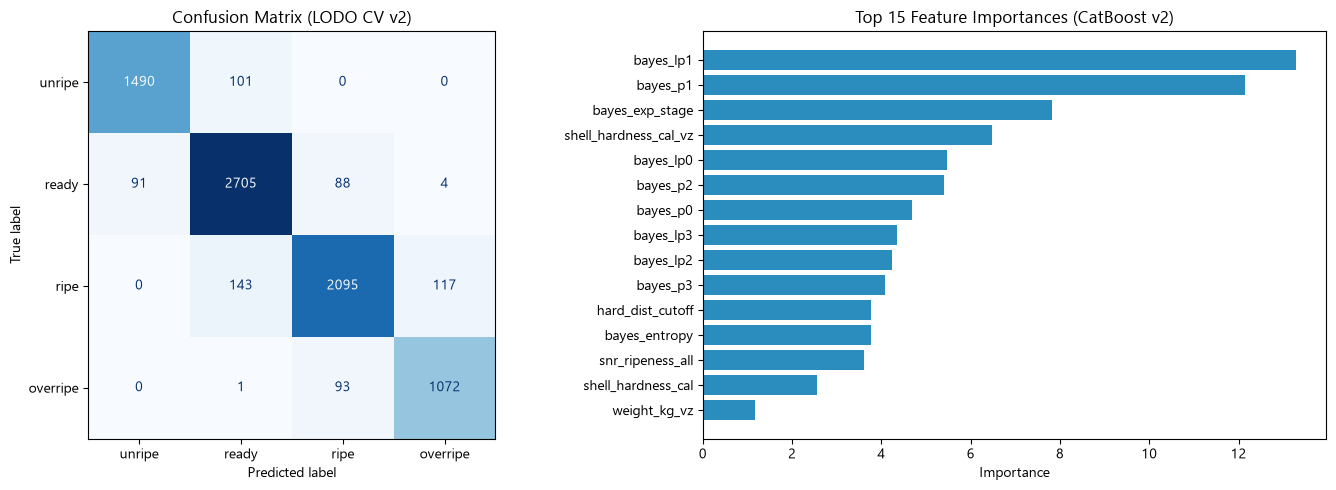

In [6]:
oof_skf_list = [oof_skf[m] for m in MODEL_NAMES]
oof_lodo_list = [oof_lodo[m] for m in MODEL_NAMES]
test_list = [test_preds[m] for m in MODEL_NAMES]

# หาค่าน้ำหนักผสมผสานบน LODO OOF (ลด LogLoss พร้อม L2 penalty เพื่อความเสถียรข้ามเครื่องวัด)
def lodo_blend_obj(raw_w):
    w = np.exp(raw_w) / np.sum(np.exp(raw_w))
    blend = sum(wi * pi for wi, pi in zip(w, oof_lodo_list))
    ll = log_loss(y_train, np.clip(blend, 1e-6, 1.0), sample_weight=variety_sample_weights)
    return ll + 0.002 * np.sum((w - 1.0 / len(MODEL_NAMES)) ** 2)

res_w = minimize(lodo_blend_obj, np.zeros(len(MODEL_NAMES)), method='BFGS')
best_w = np.exp(res_w.x) / np.sum(np.exp(res_w.x))

print("น้ำหนัก Ensemble (Optimize บน Test-Variety-Weighted LODO):")
for m, wi in zip(MODEL_NAMES, best_w):
    print(f"  {m:<18}: {wi:.4f}")

ens_oof_skf = sum(wi * pi for wi, pi in zip(best_w, oof_skf_list))
ens_oof_lodo = sum(wi * pi for wi, pi in zip(best_w, oof_lodo_list))
ens_test = sum(wi * pi for wi, pi in zip(best_w, test_list))

raw_f1_skf = f1_score(y_train, ens_oof_skf.argmax(1), average='macro')
raw_f1_lodo = f1_score(y_train, ens_oof_lodo.argmax(1), average='macro')
raw_f1_lodo_w = f1_score(y_train, ens_oof_lodo.argmax(1), average='macro', sample_weight=variety_sample_weights)
print(f"\nEnsemble (argmax มาตรฐาน) | SKF-10: {raw_f1_skf:.5f} | LODO: {raw_f1_lodo:.5f} | TestVar-LODO: {raw_f1_lodo_w:.5f}")

# ทดสอบ Multiplier แบบจำกัดช่วงแคบ [0.92, 1.08] ด้วย Nested LODO (หาจาก 3 เครื่อง -> วัดบนเครื่องที่ 4)
def fit_safe_multipliers(probs, y_true, sw=None):
    mult = np.ones(4)
    for _ in range(2):
        for c in range(4):
            grid = np.linspace(0.92, 1.08, 33)
            scores = [f1_score(y_true, (probs * np.where(np.arange(4)==c, g, mult)).argmax(1),
                               average='macro', sample_weight=sw) for g in grid]
            mult[c] = grid[int(np.argmax(scores))]
    return mult / mult.mean()

nested_lodo_preds = np.zeros(len(y_train), dtype=int)
fold_mults = []
for tr_idx, va_idx in logo.split(train_clean, y_train, groups=devices_train):
    m_f = fit_safe_multipliers(ens_oof_lodo[tr_idx], y_train[tr_idx], sw=variety_sample_weights[tr_idx])
    fold_mults.append(m_f)
    nested_lodo_preds[va_idx] = (ens_oof_lodo[va_idx] * m_f).argmax(1)

nested_f1_lodo_w = f1_score(y_train, nested_lodo_preds, average='macro', sample_weight=variety_sample_weights)
if nested_f1_lodo_w > raw_f1_lodo_w + 0.0005:
    final_mult = np.mean(fold_mults, axis=0)
    print(f"Nested LODO ดีขึ้นเป็น {nested_f1_lodo_w:.5f} -> ใช้ Safe Multipliers: {np.round(final_mult, 4)}")
else:
    final_mult = np.ones(4)
    print(f"Nested LODO ({nested_f1_lodo_w:.5f}) ไม่ต่างจาก argmax มาตรฐาน -> ใช้ argmax มาตรฐาน [1, 1, 1, 1] เพื่อกัน Overfit")

final_skf_preds = (ens_oof_skf * final_mult).argmax(1)
final_lodo_preds = (ens_oof_lodo * final_mult).argmax(1)

print(f"\nคะแนนสุดท้าย | SKF-10: {f1_score(y_train, final_skf_preds, average='macro'):.5f} | LODO: {f1_score(y_train, final_lodo_preds, average='macro'):.5f} | TestVar-LODO: {f1_score(y_train, final_lodo_preds, average='macro', sample_weight=variety_sample_weights):.5f}")

print("\nผล LODO แยกรายเครื่องวัด:")
for d in sorted(np.unique(devices_train)):
    mask = (devices_train == d)
    print(f"  Device {d}: Macro-F1 = {f1_score(y_train[mask], final_lodo_preds[mask], average='macro'):.5f}")

print("\nผล LODO แยกรายสายพันธุ์:")
for v in ['kanyao', 'monthong', 'chanee', 'puangmanee']:
    mask = (train_df['variety'].values == v)
    print(f"  {v:<12}: Macro-F1 = {f1_score(y_train[mask], final_lodo_preds[mask], average='macro'):.5f}")

print("\nClassification Report (LODO Ensemble v2):")
print(classification_report(y_train, final_lodo_preds, target_names=CLASSES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_train, final_lodo_preds)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix (LODO CV v2)')

imp_df = pd.DataFrame({'feature': feat_cols, 'importance': cat_importances}).sort_values('importance', ascending=True).tail(15)
axes[1].barh(imp_df['feature'], imp_df['importance'], color='#2b8cbe')
axes[1].set_title('Top 15 Feature Importances (CatBoost v2)')
axes[1].set_xlabel('Importance')
plt.tight_layout()
plt.show()

### 7. สร้างและตรวจสอบไฟล์ส่งคำตอบ (Generate & Verify Submission)

In [7]:
test_pred_idx = (ens_test * final_mult).argmax(1)
test_pred_labels = [INV_LABEL_MAP[i] for i in test_pred_idx]

submission = pd.DataFrame({
    'id': test_df['id'].values,
    'ripeness': test_pred_labels
})

assert len(submission) == len(sub_df), "จำนวนแถวไม่ตรงกับ sample_submission.csv"
assert list(submission.columns) == ['id', 'ripeness'], "ชื่อคอลัมน์ไม่ถูกต้อง"
assert (submission['id'].values == sub_df['id'].values).all(), "ลำดับ id ไม่ตรงกับ sample_submission.csv"
assert submission['ripeness'].isna().sum() == 0, "พบค่าว่างในคำทำนาย"
assert set(submission['ripeness'].unique()).issubset(set(CLASSES)), "พบชื่อคลาสที่ไม่ถูกต้อง"

submission.to_csv('submission.csv', index=False)
print("บันทึกไฟล์ submission.csv (v2) เรียบร้อยแล้ว")

comp_df = pd.DataFrame({
    'Train (%)': train_df['ripeness'].value_counts(normalize=True).reindex(CLASSES) * 100,
    'Test All (%)': submission['ripeness'].value_counts(normalize=True).reindex(CLASSES) * 100,
    'Test D1-D4 (%)': submission.loc[test_df['device_id'] != 'D5', 'ripeness'].value_counts(normalize=True).reindex(CLASSES) * 100,
    'Test D5 (New) (%)': submission.loc[test_df['device_id'] == 'D5', 'ripeness'].value_counts(normalize=True).reindex(CLASSES) * 100,
}).round(2)
display(comp_df)
display(submission.head(10))

บันทึกไฟล์ submission.csv (v2) เรียบร้อยแล้ว


,Train (%),Test All (%),Test D1-D4 (%),Test D5 (New) (%)
ripeness,,,,
unripe,19.89,20.03,18.51,22.86
ready,36.10,34.37,35.59,32.10
ripe,29.44,30.60,30.62,30.57
overripe,14.58,15.00,15.28,14.48


,id,ripeness
0,129497,unripe
1,121497,ready
2,992204,unripe
3,518032,overripe
4,279666,ready
5,243609,ready
6,852512,ready
7,794525,ripe
8,493626,ripe
9,963410,ready
